# Análisis exploratorio de eventos Wyscout

Los datos corresponden a la temporada 2017/18 e incluyen los 380 partidos de la Premier League. Ademas contiene 643.150 eventos.

**Contenido**
1. Configuración
2. Carga de datos
3. Vista general de los eventos
4. Futbolistas por posición
5. Acciones por jugador
6. Subeventos

> Para analizar otro torneo, cambia `TORNEO` en la sección 1 y vuelve a ejecutar el cuaderno.

## 1. Configuración

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from analisis_exploratorio import contar_acciones_por_jugador, contar_subeventos
from analisis_exploratorio import contar_eventos
from cargar_eventos import cargar_eventos, cargar_jugadores, cargar_equipos

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 12)

CARPETA_BASE = Path.cwd()
CARPETA_DATOS = CARPETA_BASE / "data" / "events"
TORNEO = "England"  # Italy, England, Germany, France, Spain, European_Championship, World_Cup
ARCHIVO_EVENTOS = CARPETA_DATOS / f"events_{TORNEO}.json"
ARCHIVO_JUGADORES = CARPETA_BASE / "data" / "players.json"
ARCHIVO_EQUIPOS = CARPETA_BASE / "data" / "teams.json"

print(f"Torneo: {TORNEO}")
print(f"Eventos:   {ARCHIVO_EVENTOS.name}")
print(f"Jugadores: {ARCHIVO_JUGADORES.name}")

Torneo: England
Eventos:   events_England.json
Jugadores: players.json


## 2. Carga de datos

Se cargan los eventos del torneo y el catálogo de jugadores. El nombre de cada jugador se añade a la tabla de eventos a partir de su `playerId`; los eventos sin jugador se etiquetan como `Sin identificar`.

In [ ]:
eventos, df_eventos = cargar_eventos(ARCHIVO_EVENTOS)
df_jugadores = cargar_jugadores(ARCHIVO_JUGADORES)
df_equipos = cargar_equipos(ARCHIVO_EQUIPOS)

nombres_jugadores = df_jugadores.set_index("wyId")["playerName"]
df_eventos["playerName"] = (
    df_eventos["playerId"].map(nombres_jugadores).fillna("Sin identificar")
)

print(f"Eventos cargados: {len(eventos):,}")
print(f"Jugadores en el catálogo: {len(df_jugadores):,}")

Eventos cargados: 643,150
Jugadores en el catálogo: 3,603


In [3]:
#df_eventos.to_csv('data/eventos.csv', index=False)
#df_jugadores.to_csv('data/jugadores.csv', index=False)
#df_equipos.to_csv('data/equipos.csv', index=False)

## 3. Vista general de los eventos

In [4]:
print(f"Dimensiones de la tabla: {df_eventos.shape[0]:,} filas x {df_eventos.shape[1]} columnas")
print("\nColumnas disponibles:")
print(", ".join(df_eventos.columns))
print("\nVariables del dataframe de jugadores:")
print(", ".join(df_jugadores.columns))
# 643150/ (90 x 11 x 20 x 38) = 0.85
# 0.85 x 360 = 306 

Dimensiones de la tabla: 643,150 filas x 13 columnas

Columnas disponibles:
eventId, subEventName, tags, playerId, positions, matchId, eventName, teamId, matchPeriod, eventSec, subEventId, id, playerName

Variables del dataframe de jugadores:
passportArea, weight, firstName, middleName, lastName, currentTeamId, birthDate, height, role, birthArea, wyId, foot, shortName, currentNationalTeamId, playerName, position


In [5]:
df_eventos.head()

,eventId,subEventName,tags,playerId,positions,matchId,...,teamId,matchPeriod,eventSec,subEventId,id,playerName
0,8,Simple pass,[{'id': 1801}],25413,"[{'y': 49, 'x': 49}, {'y': 78, 'x': 31}]",2499719,...,1609,1H,2.758649,85,177959171,Alexandre Lacazette
1,8,High pass,[{'id': 1801}],370224,"[{'y': 78, 'x': 31}, {'y': 75, 'x': 51}]",2499719,...,1609,1H,4.946850,83,177959172,Rob Holding
2,8,Head pass,[{'id': 1801}],3319,"[{'y': 75, 'x': 51}, {'y': 71, 'x': 35}]",2499719,...,1609,1H,6.542188,82,177959173,Mesut \u00d6zil
3,8,Head pass,[{'id': 1801}],120339,"[{'y': 71, 'x': 35}, {'y': 95, 'x': 41}]",2499719,...,1609,1H,8.143395,82,177959174,Mohamed Naser Elsayed Elneny
4,8,Simple pass,[{'id': 1801}],167145,"[{'y': 95, 'x': 41}, {'y': 88, 'x': 72}]",2499719,...,1609,1H,10.302366,85,177959175,H\u00e9ctor Beller\u00edn Moruno


## 4. Futbolistas por posición

El catálogo `players.json` contiene jugadores de todas las ligas, así que se filtra a quienes tienen al menos un evento en el torneo seleccionado.

In [6]:
ids_torneo = df_eventos["playerId"].dropna().unique()
df_jugadores_torneo = df_jugadores[df_jugadores["wyId"].isin(ids_torneo)]
futbolistas_por_posicion = df_jugadores_torneo["position"].value_counts().sort_index()

print(f"Futbolistas de {TORNEO} por posición:")
for posicion, cantidad in futbolistas_por_posicion.items():
    print(f"  {posicion}: {cantidad:,}")

Futbolistas de England por posición:
  Defender: 177
  Forward: 108
  Goalkeeper: 38
  Midfielder: 191


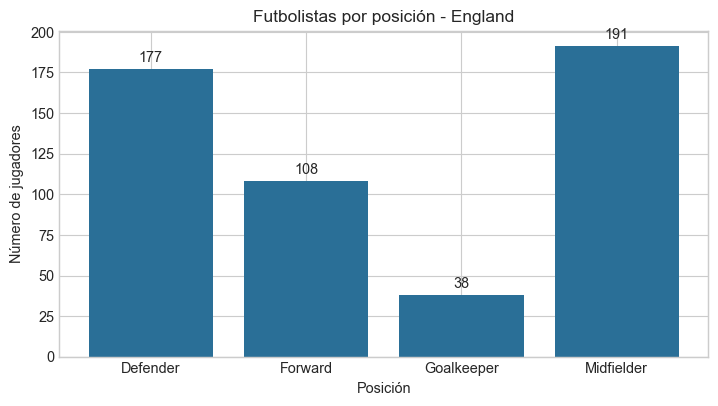

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(futbolistas_por_posicion.index, futbolistas_por_posicion.values, color="#2a6f97")
ax.bar_label(barras, padding=3)
ax.set_title(f"Futbolistas por posición - {TORNEO}")
ax.set_xlabel("Posición")
ax.set_ylabel("Número de jugadores")
plt.tight_layout()
plt.show()

## 5. Acciones por jugador

Se cuentan los eventos de cada jugador identificado (se excluyen `playerId` nulos o 0).

In [8]:
acciones_por_jugador = contar_acciones_por_jugador(df_eventos)

if acciones_por_jugador.empty:
    print("No hay eventos con un jugador identificado.")
else:
    minimo = acciones_por_jugador.min()
    maximo = acciones_por_jugador.max()
    jugadores_minimo = acciones_por_jugador[acciones_por_jugador == minimo].index.tolist()
    jugadores_maximo = acciones_por_jugador[acciones_por_jugador == maximo].index.tolist()

    print(f"Jugadores con al menos una acción: {len(acciones_por_jugador):,}")
    print(f"Media: {acciones_por_jugador.mean():,.2f} acciones por jugador")
    print(f"Máximo: {maximo:,} acciones")
    for player_id in jugadores_maximo:
        print(f"  {nombres_jugadores.get(player_id, 'Nombre no encontrado')} (playerId: {player_id})")
    print(f"Mínimo: {minimo:,} acciones")
    for player_id in jugadores_minimo:
        print(f"  {nombres_jugadores.get(player_id, 'Nombre no encontrado')} (playerId: {player_id})")

Jugadores con al menos una acción: 514
Media: 1,157.82 acciones por jugador
Máximo: 4,060 acciones
  Granit Xhaka (playerId: 49876)
Mínimo: 1 acciones
  Vincent Janssen (playerId: 269676)
  Dwight McNeil (playerId: 532949)


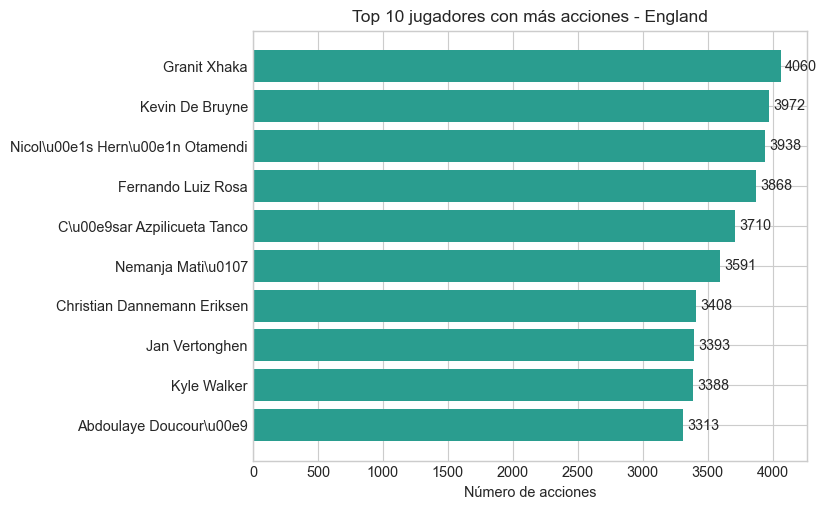

In [9]:
top_jugadores = acciones_por_jugador.nlargest(10).sort_values()
etiquetas = [nombres_jugadores.get(pid, str(pid)) for pid in top_jugadores.index]

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.barh(etiquetas, top_jugadores.values, color="#2a9d8f")
ax.bar_label(barras, padding=3)
ax.set_title(f"Top 10 jugadores con más acciones - {TORNEO}")
ax.set_xlabel("Número de acciones")
plt.tight_layout()
plt.show()

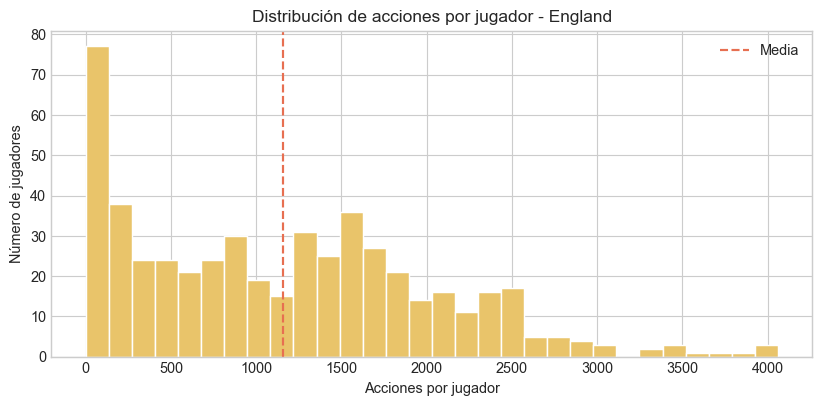

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(acciones_por_jugador.values, bins=30, color="#e9c46a", edgecolor="white")
ax.axvline(acciones_por_jugador.mean(), color="#e76f51", linestyle="--", label="Media")
ax.set_title(f"Distribución de acciones por jugador - {TORNEO}")
ax.set_xlabel("Acciones por jugador")
ax.set_ylabel("Número de jugadores")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Subeventos y eventos

Número de tipos de subevento distintos asociados a cada evento.

In [11]:
subeventos_por_evento = (
    df_eventos.dropna(subset=["eventName", "subEventName"])
    .groupby("eventName")["subEventName"]
    .nunique()
    .sort_values(ascending=False)
    .rename("cantidad_subeventos")
    .to_frame()
)

subeventos_por_evento

,cantidad_subeventos
eventName,
Foul,8
Free Kick,7
Pass,7
Duel,4
Others on the ball,3
Interruption,2
Save attempt,2
Goalkeeper leaving line,1
Offside,1


In [12]:
subeventos = contar_subeventos(df_eventos)

print(f"Tipos de subevento distintos: {len(subeventos):,}")
print(f"Registros con nombre de subevento: {subeventos.sum():,}")
subeventos.sort_values(ascending=False).rename("frecuencia").to_frame()

Tipos de subevento distintos: 35
Registros con nombre de subevento: 641,592


,frecuencia
subEventName,
Simple pass,251405
Ground attacking duel,53859
Ground defending duel,53737
Air duel,37760
Touch,34409
Ground loose ball duel,31332
Ball out of the field,27331
High pass,25067
Head pass,21332


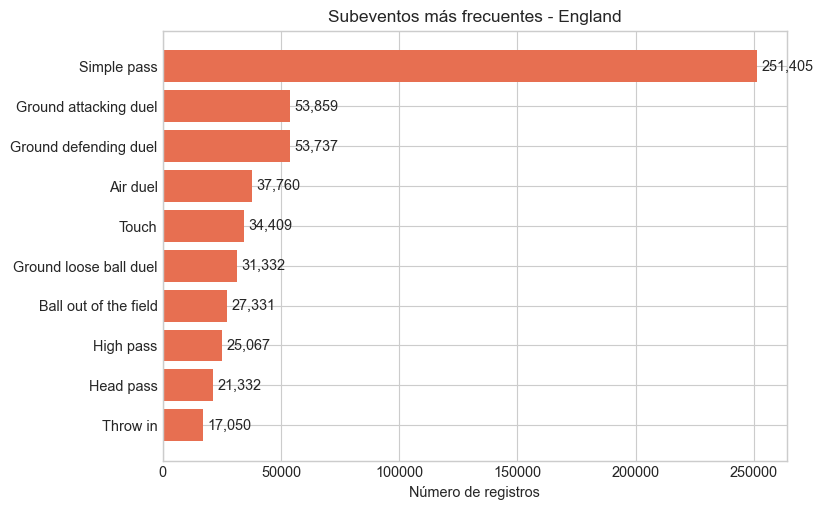

In [13]:
top_subeventos = subeventos.nlargest(10).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.barh(top_subeventos.index, top_subeventos.values, color="#e76f51")
ax.bar_label(barras, padding=3, fmt="{:,.0f}")
ax.set_title(f"Subeventos más frecuentes - {TORNEO}")
ax.set_xlabel("Número de registros")
plt.tight_layout()
plt.show()

In [14]:
import json
from collections import Counter
import pandas as pd

with ARCHIVO_EVENTOS.open(encoding="utf-8") as f:
    eventos = json.load(f)

tags2name = pd.read_csv(CARPETA_BASE / "data" / "tags2name.csv", sep=";").set_index("Tag")["Description"]

tags_por_subevento = {}
frecuencias = Counter()
for e in eventos:
    subevento = e["subEventName"] or "(vacío)"
    tags = {t["id"] for t in e["tags"]}
    tags_por_subevento.setdefault(subevento, set()).update(tags)
    frecuencias.update((subevento, tag) for tag in tags)

df_subeventos_tags = pd.DataFrame(
    [
        {"frecuencia": frecuencias[(subevento, tag)], "subevento": subevento, "tag": tags2name.get(tag, "?")}
        for subevento, tags in sorted(tags_por_subevento.items())
        for tag in sorted(tags)
    ]
).sort_values(["subevento", "tag"]).reset_index(drop=True)

with pd.option_context("display.max_rows", None):
    display(df_subeventos_tags)

,frecuencia,subevento,tag
0,31,(vacío),Counter attack
1,4574,Acceleration,Accurate
2,915,Acceleration,Counter attack
3,244,Acceleration,Interception
4,318,Acceleration,Not accurate
5,20768,Air duel,Accurate
6,16,Air duel,Assist
7,234,Air duel,Counter attack
8,55,Air duel,Key pass
9,16982,Air duel,Lost


## Detección de nulos

In [15]:
df_eventos.isna().sum().rename("nulos").to_frame()

,nulos
eventId,0
subEventName,0
tags,0
playerId,0
positions,0
matchId,0
eventName,0
teamId,0
matchPeriod,0
eventSec,0


In [16]:
df_jugadores.isna().sum().rename("nulos").to_frame()

,nulos
passportArea,0
weight,0
firstName,0
middleName,0
lastName,0
currentTeamId,91
birthDate,0
height,0
role,0
birthArea,0


## Eventos por jugador 

Vamos a eliminar todos aquellos eventos de la tabla df_eventos cuyos tags solo aparezcan 10 veces o menos 

In [17]:
from collections import Counter

def contar_pares(df):
    frecuencias = Counter()

    for subevento, tags in df[["subEventName", "tags"]].itertuples(
        index=False, name=None
    ):
        nombre = "(vacío)" if pd.isna(subevento) or not subevento else subevento
        frecuencias.update(
            (nombre, tag_id) for tag_id in {tag["id"] for tag in tags}
        )

    return frecuencias


frecuencias = contar_pares(df_eventos)
pares_raros = {
    par for par, frecuencia in frecuencias.items() if frecuencia <= 10
}

conservar = []
for subevento, tags in df_eventos[["subEventName", "tags"]].itertuples(
    index=False, name=None
):
    nombre = "(vacío)" if pd.isna(subevento) or not subevento else subevento
    conservar.append(
        not any((nombre, tag["id"]) in pares_raros for tag in tags)
    )

antes = len(df_eventos)
df_eventos = df_eventos.loc[conservar].copy()
print(f"Registros eliminados: {antes - len(df_eventos):,}")
print(f"Registros restantes: {len(df_eventos):,}")

tags2name = pd.read_csv(
    CARPETA_BASE / "data" / "tags2name.csv", sep=";"
).set_index("Tag")["Description"]

df_subeventos_tags = pd.DataFrame(
    [
        {
            "frecuencia": frecuencia,
            "subevento": subevento,
            "tag": tags2name.get(tag_id, f"Desconocido ({tag_id})"),
        }
        for (subevento, tag_id), frecuencia in contar_pares(df_eventos).items()
    ],
    columns=["frecuencia", "subevento", "tag"],
).sort_values(["subevento", "tag"]).reset_index(drop=True)

with pd.option_context("display.max_rows", None):
    display(df_subeventos_tags)

Registros eliminados: 224
Registros restantes: 642,926


,frecuencia,subevento,tag
0,31,(vacío),Counter attack
1,4574,Acceleration,Accurate
2,915,Acceleration,Counter attack
3,244,Acceleration,Interception
4,318,Acceleration,Not accurate
5,20768,Air duel,Accurate
6,16,Air duel,Assist
7,234,Air duel,Counter attack
8,55,Air duel,Key pass
9,16982,Air duel,Lost


## Jugadores con al menos 306 eventos

Se cuentan los eventos que quedan tras la limpieza anterior y se conservan los jugadores identificados con 306 o más registros.

In [18]:
eventos_por_jugador = df_eventos.loc[
    df_eventos["playerId"].notna() & df_eventos["playerId"].ne(0), "playerId"
].value_counts()
ids_jugadores = eventos_por_jugador[eventos_por_jugador >= 306].index
ids_jugadores = ids_jugadores[ids_jugadores.isin(df_jugadores["wyId"])]

eventos_antes = len(df_eventos)
jugadores_antes = len(df_jugadores)
df_eventos = df_eventos.loc[df_eventos["playerId"].isin(ids_jugadores)].copy()
df_jugadores = df_jugadores.loc[df_jugadores["wyId"].isin(ids_jugadores)].copy()

print(f"Jugadores conservados: {len(df_jugadores):,} de {jugadores_antes:,}")
print(f"Eventos eliminados: {eventos_antes - len(df_eventos):,}")
print(f"Eventos restantes: {len(df_eventos):,}")

Jugadores conservados: 394 de 3,603
Eventos eliminados: 61,534
Eventos restantes: 581,392


## Jugadores por posición tras la limpieza

Número de jugadores identificados en el torneo y conservados tras el filtro de 306 eventos, según su posición en el catálogo.

In [19]:
tabla_jugadores_posicion = (
    df_jugadores.loc[df_jugadores["wyId"].isin(df_eventos["playerId"])]
    .groupby("position", dropna=False)["wyId"]
    .nunique()
    .sort_index()
    .rename("numero_jugadores")
    .to_frame()
)
tabla_jugadores_posicion

,numero_jugadores
position,
Defender,143
Forward,75
Goalkeeper,27
Midfielder,149


## Tratamiento de los datos
Modificamos las tablas para quedarnos con lo que más nos interese para el análisis posterior


### Modificar eventos

In [30]:
from modificar_datos import decodificar_nombre, procesar_tags, extraer_posiciones

# Hacemos una copia
df_eventos_fixed = df_eventos.copy()

# Decodificamos los nombres que estaban mal
df_eventos_fixed['playerName'] = df_eventos_fixed['playerName'].apply(decodificar_nombre)

# Si eventName es Offside ponemos subEventName a Offside para evitar nulos
df_eventos_fixed.loc[df_eventos_fixed['eventName'] == 'Offside', 'subEventName'] = 'Offside'

# Creamos un diccionario con el tags2name para que la sustitución sea mejor
tags_dict = tags2name.to_dict()

# Cambiamos todos los tags por su significado
df_eventos_fixed['tags'] = df_eventos_fixed['tags'].apply(lambda x: procesar_tags(x, tags_dict))

# Separamos en dos columnas la posicion, una para el inicio y una para el final
df_eventos_fixed[['pos_inicio_x', 'pos_inicio_y', 'pos_fin_x', 'pos_fin_y']] = df_eventos_fixed['positions'].apply(extraer_posiciones)

df_eventos_fixed['pos_inicio'] = df_eventos_fixed.apply(lambda row: f"(X: {row['pos_inicio_x']}, Y: {row['pos_inicio_y']})" if pd.notna(row['pos_inicio_x']) else "", axis=1)
df_eventos_fixed['pos_fin'] = df_eventos_fixed.apply(lambda row: f"(X: {row['pos_fin_x']}, Y: {row['pos_fin_y']})" if pd.notna(row['pos_fin_x']) else "", axis=1)

# Seleccionamos las columnas que nos quedaremos finalmente
columnas_finales = [
    'id',
    'eventName',
    'subEventName',
    'tags',
    'pos_inicio',
    'pos_fin',
    'matchPeriod',
    'eventSec',
    'playerName',
    'playerId',
    'teamId',
    'matchId'
]

df_eventos_fixed = df_eventos_fixed[columnas_finales]

nombre_archivo = 'data/eventos_fixed.csv'
df_eventos_fixed.to_csv(nombre_archivo, index=False, encoding='utf-8-sig')

### Modificar jugadores

In [31]:
from modificar_datos import extraer_pais_nacimiento

df_jugadores_fixed = df_jugadores.copy()

#Renombramos la columna wyId a playerId
df_jugadores_fixed.rename(columns={'wyId': 'playerId'}, inplace=True)

# Decodificamos el nombre
df_jugadores_fixed['playerName'] = df_jugadores_fixed['playerName'].apply(decodificar_nombre)

# Los jugadores sin introducir su pie dominante les ponemos ambos
df_jugadores_fixed['foot'] = df_jugadores_fixed['foot'].fillna('both')
df_jugadores_fixed.loc[df_jugadores_fixed['foot'].astype(str).str.strip() == '', 'foot'] = 'both'

# Guardamos su país de nacimiento
df_jugadores_fixed['birthCountry'] = df_jugadores_fixed['birthArea'].apply(extraer_pais_nacimiento)

columnas_jugadores_finales = [
    'playerId',
    'playerName',
    'currentTeamId',
    'position',
    'foot',
    'height',
    'weight',
    'birthDate',
    'birthCountry'
]

df_jugadores_final = df_jugadores_fixed[columnas_jugadores_finales]

archivo_salida = 'data/jugadores_fixed.csv'
df_jugadores_final.to_csv(archivo_salida, index=False, encoding='utf-8-sig')



### Modificar equipos

In [34]:
from modificar_datos import extraer_nombre_area

df_equipos_fixed = df_equipos.copy()

df_equipos_fixed.rename(columns={
    'wyId': 'teamId',
    'officialName': 'teamName'
}, inplace=True)

df_equipos_fixed['teamName'] = df_equipos_fixed['teamName'].apply(decodificar_nombre)

df_equipos_fixed['area_name'] = df_equipos_fixed['area'].apply(extraer_nombre_area)

condicion_club_ingles_gales = (
    (df_equipos_fixed['type'].str.lower() != 'national') & 
    (df_equipos_fixed['area_name'].isin(['England', 'Wales']))
)

df_equipos_fixed = df_equipos_fixed[condicion_club_ingles_gales]

columnas_equipos_finales = [
    'teamId',
    'teamName'
]

df_equipos_final = df_equipos_fixed[columnas_equipos_finales]

archivo_salida = 'data/equipos_fixed.csv'
df_equipos_final.to_csv(archivo_salida, index=False, encoding='utf-8-sig')
